
# AI-Based Customer Spending Prediction

**Internship:** VEDA AI/ML Internship  
**Day:** 32 of 45  
**Project Day:** 2 of 4  
**Date:** 21 October 2026

## Objective
To analyze customer demographic and purchasing-related information and classify customers into Low, Medium, or High spending categories using machine learning.

## Workflow
1. Dataset collection
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature engineering
5. Classification model training
6. Model evaluation and comparison
7. Prediction for new customers
8. Business insights


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = (
    "https://raw.githubusercontent.com/"
    "MahimaSriK/Mall-Customer-Segmentation-Dataset/"
    "main/Mall_Customers.csv"
)

df = pd.read_csv(url)

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 5)


,customerid,gender,age,annual_income_k,spending_score_1_100
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df = pd.read_csv("Mall_Customers.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Mall_Customers.csv'

In [4]:

import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())


HTTPError: HTTP Error 404: Not Found

In [5]:
import os

print("Current working folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current working folder:
C:\Users\Divakar

Files in this folder:
['.anaconda', '.arduinoIDE', '.cache', '.codex', '.conda', '.copilot', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.Ld9VirtualBox', '.m2', '.matplotlib', '.ms-ad', '.opera', '.ssh', '.streamlit', '.vscode', '.vscode-shared', 'AIML.txt', 'AI_vs_ML_vs_Deep_Learning.ipynb', 'anaconda3', 'AppData', 'Application Data', 'boxplot.png', 'breadth first search.py', 'CLOAK_CV-VISION', 'Contacts', 'Cookies', 'CrossDevice', 'customer_spending_prediction.ipynb', 'dataset.csv', 'Day-11-NumPy-Student-Marks.ipynb', 'Day-12-NumPy-Array-Operations.ipynb', 'Day-13-NumPy-Data-Filtering.ipynb', 'Day_14_NumPy_Matrix_Operations.ipynb', 'Day_15_NumPy_Statistical_Analysis.ipynb', 'Day_22_Handle_Missing_Values.ipynb', 'Day_23_Duplicate_Data_Removal.ipynb', 'Day_9_Python_Data_Processing.ipynb', 'Desktop', 'detect.py', 'divbot.py', 'Documents', 'Downloads', 'duplicate_data_cleaned.csv', 'Employee_Salary_Analysis.ipynb', 'Fa

In [6]:
df = pd.read_csv(
    r"C:\Users\YOUR_USERNAME\Downloads\Mall_Customers.csv"
)

display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\YOUR_USERNAME\\Downloads\\Mall_Customers.csv'

In [7]:

import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/Mall_Customers.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
except Exception as e:
    print("Dataset loading failed:", e)


Dataset loading failed: HTTP Error 404: Not Found


In [8]:

import pandas as pd

url = "https://raw.githubusercontent.com/DataThinkers/Datasets/main/DS/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset shape: (200, 5)

Column names:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [9]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['customerid', 'genre', 'age', 'annual_income_k', 'spending_score_1_100']


In [10]:

df = df.rename(columns={
    "customerid": "customer_id",
    "genre": "gender",
    "annual_income_k": "annual_income",
    "spending_score_1_100": "spending_score"
})

print("Updated columns:")
print(df.columns.tolist())

display(df.head())


Updated columns:
['customer_id', 'gender', 'age', 'annual_income', 'spending_score']


,customer_id,gender,age,annual_income,spending_score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (200, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customer_id     200 non-null    int64
 1   gender          200 non-null    str  
 2   age             200 non-null    int64
 3   annual_income   200 non-null    int64
 4   spending_score  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Missing values:


customer_id       0
gender            0
age               0
annual_income     0
spending_score    0
dtype: int64


Duplicate rows: 0

Statistical summary:


,customer_id,age,annual_income,spending_score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [12]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Standardize gender values
df["gender"] = df["gender"].astype("string").str.strip().str.title()

# Ensure numerical columns have numeric data types
for col in ["age", "annual_income", "spending_score"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows missing required values
df = df.dropna(
    subset=["gender", "age", "annual_income", "spending_score"]
).copy()

# Remove invalid values
df = df[
    (df["age"] > 0) &
    (df["annual_income"] >= 0) &
    (df["spending_score"].between(1, 100))
].copy()

print("Cleaning completed!")
print("Rows and columns:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum())

Cleaning completed!
Rows and columns: (200, 5)

Missing values after cleaning:


customer_id       0
gender            0
age               0
annual_income     0
spending_score    0
dtype: int64

In [13]:
def categorize_spending(score):
    if score <= 33:
        return "Low"
    elif score <= 66:
        return "Medium"
    else:
        return "High"

df["spending_category"] = df["spending_score"].apply(
    categorize_spending
)

print("Customer spending categories:")
display(df["spending_category"].value_counts().to_frame("Count"))

display(df.head(10))

Customer spending categories:


,Count
spending_category,
Medium,94
High,57
Low,49


,customer_id,gender,age,annual_income,spending_score,spending_category
0,1,Male,19,15,39,Medium
1,2,Male,21,15,81,High
2,3,Female,20,16,6,Low
3,4,Female,23,16,77,High
4,5,Female,31,17,40,Medium
5,6,Female,22,17,76,High
6,7,Female,35,18,6,Low
7,8,Female,23,18,94,High
8,9,Male,64,19,3,Low
9,10,Female,30,19,72,High


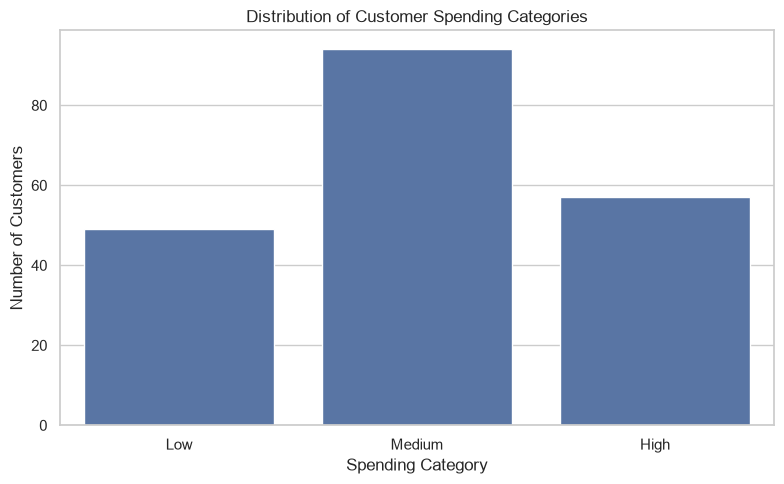

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

sns.countplot(
    data=df,
    x="spending_category",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Customer Spending Categories")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

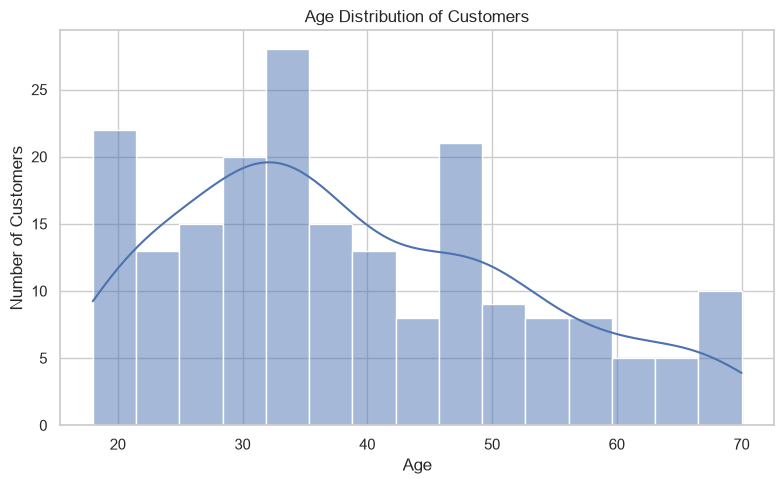

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=15, kde=True)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

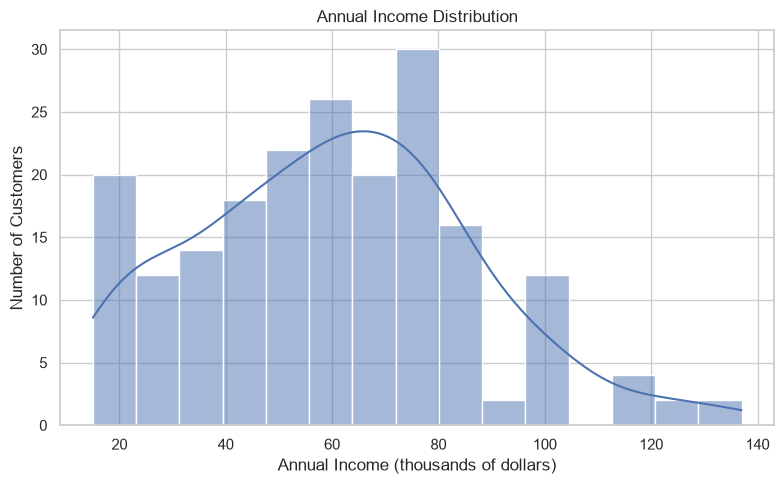

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="annual_income", bins=15, kde=True)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

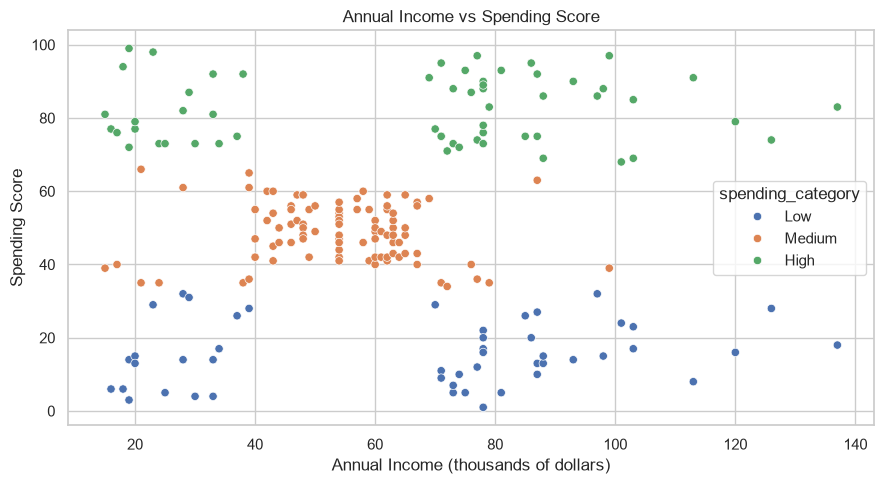

In [17]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="annual_income",
    y="spending_score",
    hue="spending_category",
    hue_order=["Low", "Medium", "High"]
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score")
plt.tight_layout()
plt.show()

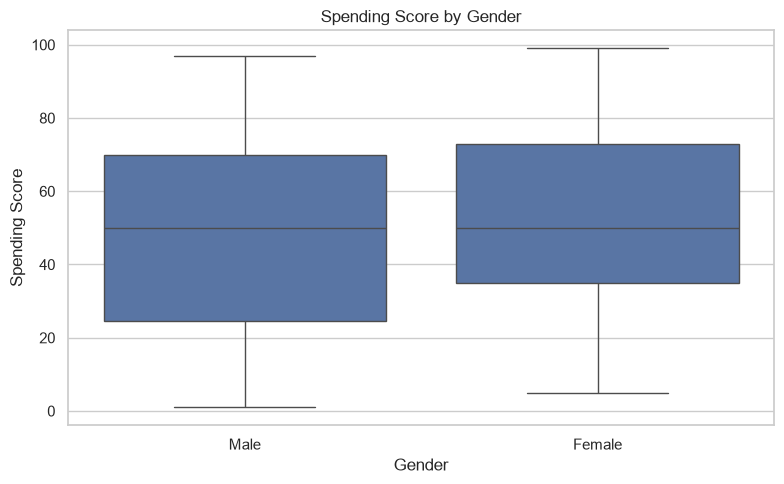

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="gender",
    y="spending_score"
)

plt.title("Spending Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Spending Score")
plt.tight_layout()
plt.show()

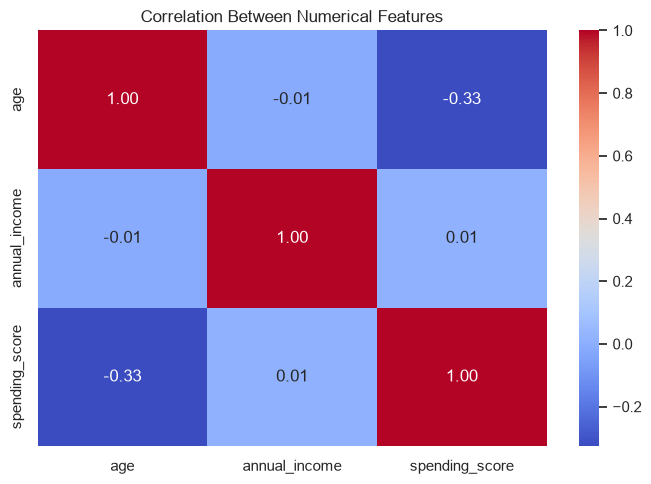

In [19]:
plt.figure(figsize=(7, 5))

numeric_data = df[
    ["age", "annual_income", "spending_score"]
]

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [20]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 40, 60, float("inf")],
    labels=["Young", "Adult", "Middle-aged", "Senior"]
)

df["income_group"] = pd.cut(
    df["annual_income"],
    bins=[-float("inf"), 40, 70, float("inf")],
    labels=["Low Income", "Medium Income", "High Income"]
)

display(df.head())

,customer_id,gender,age,annual_income,spending_score,spending_category,age_group,income_group
0,1,Male,19,15,39,Medium,Young,Low Income
1,2,Male,21,15,81,High,Young,Low Income
2,3,Female,20,16,6,Low,Young,Low Income
3,4,Female,23,16,77,High,Young,Low Income
4,5,Female,31,17,40,Medium,Adult,Low Income


In [21]:
print("Average spending score by age group:")

display(
    df.groupby("age_group", observed=True)["spending_score"]
      .mean()
      .round(2)
      .to_frame("Average Spending Score")
)

print("Average spending score by income group:")

display(
    df.groupby("income_group", observed=True)["spending_score"]
      .mean()
      .round(2)
      .to_frame("Average Spending Score")
)

Average spending score by age group:


,Average Spending Score
age_group,
Young,54.95
Adult,61.26
Middle-aged,33.69
Senior,44.18


Average spending score by income group:


,Average Spending Score
income_group,
Low Income,49.48
Medium Income,50.68
High Income,50.19


In [22]:
df.to_csv("customer_spending_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [23]:
from sklearn.model_selection import train_test_split

X = df[["age", "annual_income", "gender"]].copy()
y = df["spending_category"].copy()

print("Input features:", X.columns.tolist())
print("\nTarget categories:")
print(y.value_counts())

print("\nTotal records:", len(df))

Input features: ['age', 'annual_income', 'gender']

Target categories:
spending_category
Medium    94
High      57
Low       49
Name: count, dtype: int64

Total records: 200


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [25]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = ["age", "annual_income"]
categorical_features = ["gender"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=4,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(3))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.525,0.528,0.467,0.474
Decision Tree,0.750,0.768,0.733,0.724


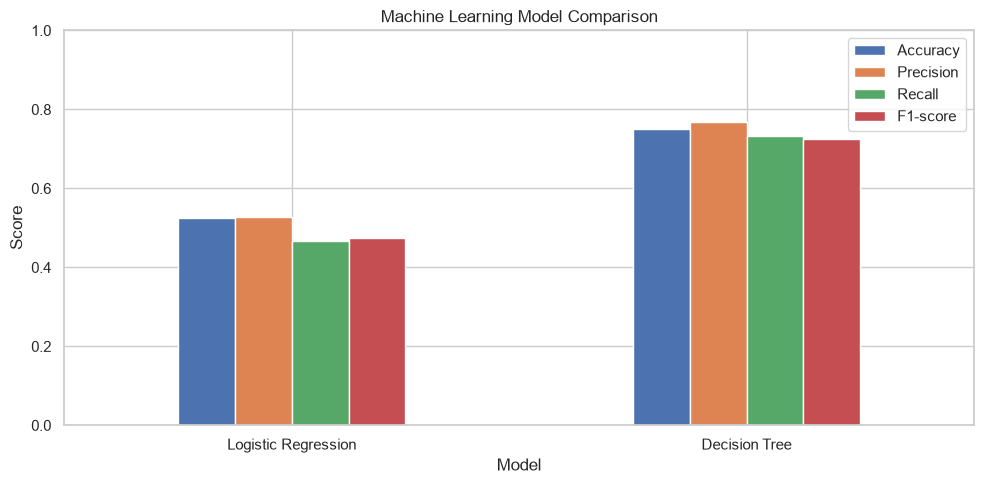

In [28]:
results_df.plot(kind="bar", ylim=(0, 1), figsize=(10, 5))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Selected model: Decision Tree

Classification report:
              precision    recall  f1-score   support

         Low       0.83      0.50      0.62        10
      Medium       0.88      0.79      0.83        19
        High       0.59      0.91      0.71        11

    accuracy                           0.75        40
   macro avg       0.77      0.73      0.72        40
weighted avg       0.79      0.75      0.75        40



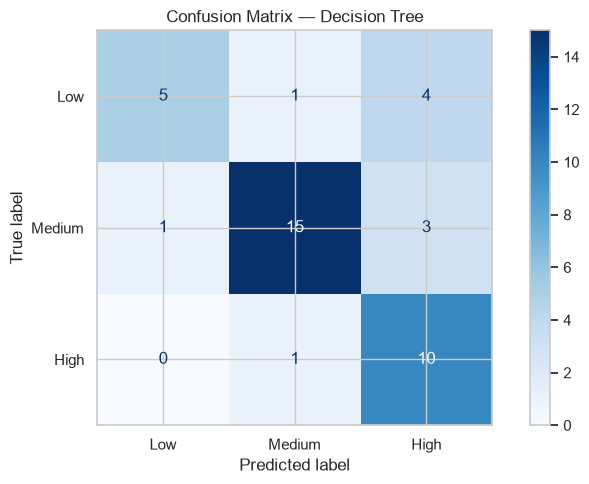

In [29]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

best_model_name = results_df["F1-score"].idxmax()
best_model = models[best_model_name]
best_predictions = predictions[best_model_name]

print("Selected model:", best_model_name)
print("\nClassification report:")

print(classification_report(
    y_test,
    best_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Medium", "High"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

display_matrix.plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

,Feature,Importance
1,num__annual_income,0.546743
0,num__age,0.442452
3,cat__gender_Male,0.010805
2,cat__gender_Female,0.000000


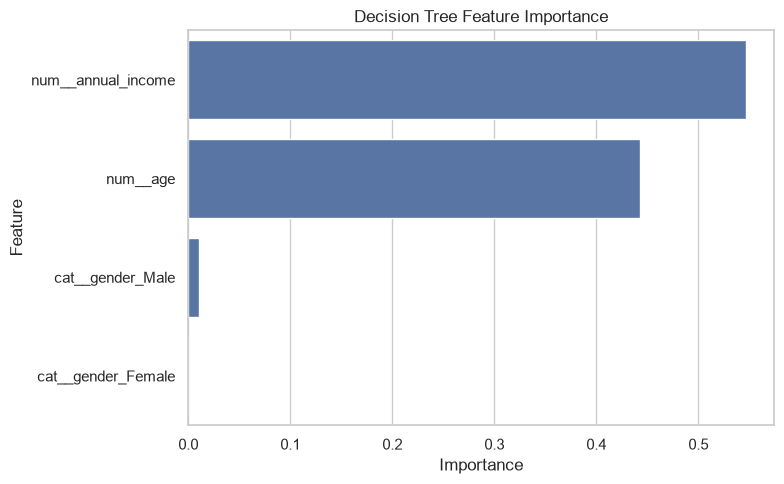

In [30]:
tree_model = models["Decision Tree"]

feature_names = (
    tree_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    tree_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df)

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

In [31]:
def predict_customer_spending(age, annual_income, gender):
    customer = pd.DataFrame([{
        "age": age,
        "annual_income": annual_income,
        "gender": gender.strip().title()
    }])

    return best_model.predict(customer)[0]


prediction = predict_customer_spending(
    age=30,
    annual_income=60,
    gender="Female"
)

print("Predicted spending category:", prediction)

Predicted spending category: Medium


In [32]:
df.to_csv("customer_spending_cleaned.csv", index=False)
results_df.to_csv("model_comparison_results.csv")

print("Saved files:")
print("1. customer_spending_cleaned.csv")
print("2. model_comparison_results.csv")
print("3. customer_spending_prediction.ipynb (save manually using Ctrl+S)")

Saved files:
1. customer_spending_cleaned.csv
2. model_comparison_results.csv
3. customer_spending_prediction.ipynb (save manually using Ctrl+S)


In [33]:

# Customer spending analysis
print("CUSTOMER SPENDING INSIGHTS")
print("=" * 40)

print("\n1. Number of customers:", len(df))

print("\n2. Spending category distribution:")
display(
    df["spending_category"]
    .value_counts()
    .rename_axis("Category")
    .to_frame("Customers")
)

print("\n3. Average spending score by category:")
display(
    df.groupby("spending_category")["spending_score"]
      .agg(["count", "mean", "median"])
      .round(2)
)

print("\n4. Average age by category:")
display(
    df.groupby("spending_category")["age"]
      .mean()
      .round(2)
)

print("\n5. Average annual income by category:")
display(
    df.groupby("spending_category")["annual_income"]
      .mean()
      .round(2)
)

print("\n6. Best model by macro F1-score:", best_model_name)
print(
    "Macro F1-score:",
    round(results_df.loc[best_model_name, "F1-score"], 3)
)


CUSTOMER SPENDING INSIGHTS

1. Number of customers: 200

2. Spending category distribution:


,Customers
Category,
Medium,94
High,57
Low,49



3. Average spending score by category:


,count,mean,median
spending_category,,,
High,57,82.35,81.0
Low,49,15.31,14.0
Medium,94,48.89,49.0



4. Average age by category:


spending_category
High      30.18
Low       42.88
Medium    42.01
Name: age, dtype: float64


5. Average annual income by category:


spending_category
High      66.07
Low       67.00
Medium    53.86
Name: annual_income, dtype: float64


6. Best model by macro F1-score: Decision Tree
Macro F1-score: 0.724



# Final Project Report: AI-Based Customer Spending Prediction

## 1. Introduction
This project demonstrates a basic machine learning workflow for classifying customers into Low, Medium, and High spending categories using demographic and purchasing-related information.

## 2. Objective
To clean customer data, perform exploratory data analysis, engineer features, train classification models, compare their performance, and predict spending categories for new customer records.

## 3. Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 4. Dataset
The Mall Customers dataset contains customer demographic information, annual income, and a numerical spending score. The spending category was created using the following project-defined ranges:
- Low: 1–33
- Medium: 34–66
- High: 67–100

## 5. Data Preprocessing
The dataset was inspected for missing values, duplicate records, invalid values, and data types. Numerical features were standardized and categorical data was one-hot encoded for model training.

## 6. Exploratory Data Analysis
Visualizations were created to analyze:
1. Spending category distribution
2. Age distribution
3. Annual income distribution
4. Annual income versus spending score
5. Spending score by gender
6. Correlation between numerical features

## 7. Feature Engineering
Age groups and income groups were created to support customer analysis.

## 8. Machine Learning Models
Two classification algorithms were trained:
- Logistic Regression
- Decision Tree Classifier

The dataset was divided into training and testing sets using an 80:20 split.

## 9. Model Evaluation
The models were evaluated using accuracy, macro precision, macro recall, macro F1-score, and a confusion matrix. The selected model was the one with the higher macro F1-score on the test set.

## 10. Feature Interpretation
Decision Tree feature importance was examined to understand how the input features contributed to model decisions.

## 11. Business Applications
- Customer segmentation
- Targeted marketing campaigns
- Personalized promotional offers
- Customer group analysis

## 12. Limitations
The target is derived from an existing spending score, not actual future spending. The dataset is small, and its findings may not generalize to other customer populations. Model performance should be interpreted cautiously.

## 13. Conclusion
The project demonstrates the fundamental machine learning workflow, including data preparation, visualization, feature engineering, classification, model evaluation, interpretation, and prediction for new customer records.


In [34]:

import os

required_files = [
    "customer_spending_cleaned.csv",
    "model_comparison_results.csv"
]

print("FINAL PROJECT VERIFICATION")
print("=" * 40)

for file in required_files:
    print(
        f"{file}:",
        "Available" if os.path.exists(file) else "Not found"
    )

print("\nEDA visualizations: Completed")
print("Classification models:", list(models.keys()))
print("Evaluation metrics:", results_df.columns.tolist())
print("Confusion matrix: Generated")
print("Feature importance: Generated")
print("Prediction function: Defined")
print("\nSelected model:", best_model_name)

print("\nRemember to save the notebook using Ctrl+S.")


FINAL PROJECT VERIFICATION
customer_spending_cleaned.csv: Available
model_comparison_results.csv: Available

EDA visualizations: Completed
Classification models: ['Logistic Regression', 'Decision Tree']
Evaluation metrics: ['Accuracy', 'Precision', 'Recall', 'F1-score']
Confusion matrix: Generated
Feature importance: Generated
Prediction function: Defined

Selected model: Decision Tree

Remember to save the notebook using Ctrl+S.



# Day 33 – Advanced Customer Spending Analysis

## Objectives
- Segment customers based on annual income and spending score.
- Visualize customer groups.
- Analyze machine learning prediction errors.
- Identify customer group characteristics.
- Generate business insights and export results.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_url = (
    "https://raw.githubusercontent.com/"
    "MahimaSriK/Mall-Customer-Segmentation-Dataset/main/"
    "Mall_Customers.csv"
)

df = pd.read_csv(data_url)

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

df.rename(columns={
    "genre": "gender",
    "annual_income_k": "annual_income"
}, inplace=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()


Dataset loaded successfully!
Shape: (200, 5)
Columns: ['customerid', 'gender', 'age', 'annual_income', 'spending_score_1_100']


,customerid,gender,age,annual_income,spending_score_1_100
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:

print(df.columns.tolist())


['customerid', 'gender', 'age', 'annual_income', 'spending_score_1_100']


In [7]:

# Normalize column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Find and rename the spending score column
spending_candidates = [
    col for col in df.columns
    if "spending" in col and "score" in col
]

if "spending_score" not in df.columns:
    if len(spending_candidates) == 1:
        df.rename(
            columns={spending_candidates[0]: "spending_score"},
            inplace=True
        )
    else:
        print("Available columns:", df.columns.tolist())
        raise ValueError(
            "Could not uniquely identify the spending score column."
        )

print("Corrected columns:", df.columns.tolist())
print("Spending score column is ready.")


Corrected columns: ['customerid', 'gender', 'age', 'annual_income', 'spending_score']
Spending score column is ready.


In [8]:
income_median = df["annual_income"].median()
spending_median = df["spending_score"].median()

In [9]:
income_median = df["annual_income"].median()
spending_median = df["spending_score"].median()

conditions = [
    (df["annual_income"] >= income_median) &
    (df["spending_score"] >= spending_median),

    (df["annual_income"] >= income_median) &
    (df["spending_score"] < spending_median),

    (df["annual_income"] < income_median) &
    (df["spending_score"] >= spending_median)
]

segment_names = [
    "High Income - High Spending",
    "High Income - Low Spending",
    "Low Income - High Spending"
]

df["customer_segment"] = np.select(
    conditions,
    segment_names,
    default="Low Income - Low Spending"
)

print("Customer segmentation completed.")
display(df["customer_segment"].value_counts())

Customer segmentation completed.


customer_segment
Low Income - High Spending     52
High Income - Low Spending     50
High Income - High Spending    50
Low Income - Low Spending      48
Name: count, dtype: int64

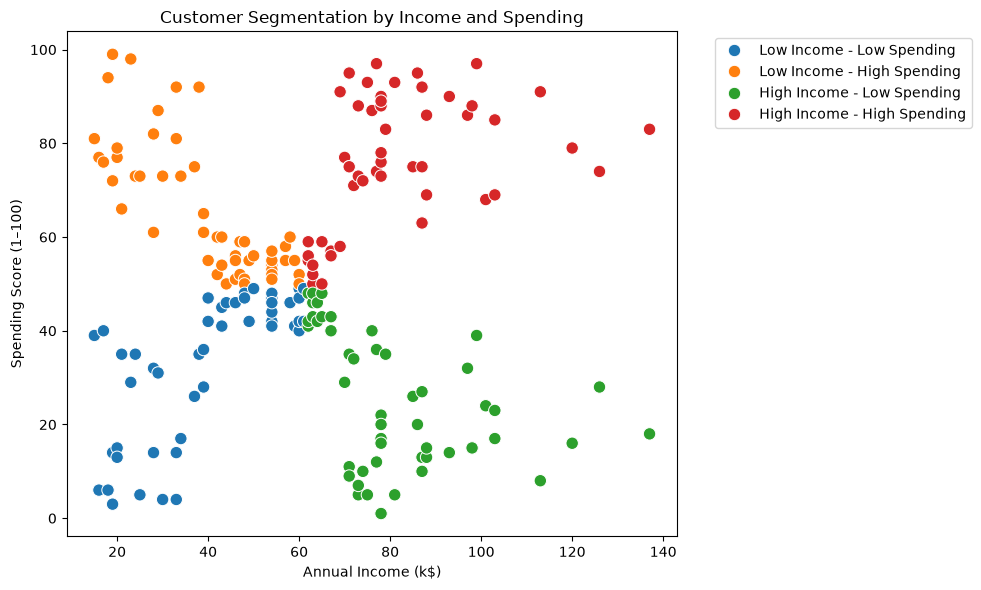

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="annual_income",
    y="spending_score",
    hue="customer_segment",
    s=80
)

plt.title("Customer Segmentation by Income and Spending")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1–100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [11]:
segment_analysis = df.groupby("customer_segment").agg(
    customer_count=("customer_segment", "count"),
    average_income=("annual_income", "mean"),
    average_spending_score=("spending_score", "mean")
).round(2)

display(segment_analysis)

,customer_count,average_income,average_spending_score
customer_segment,,,
High Income - High Spending,50,81.66,76.18
High Income - Low Spending,50,81.46,24.76
Low Income - High Spending,52,39.56,65.25
Low Income - Low Spending,48,39.56,33.33


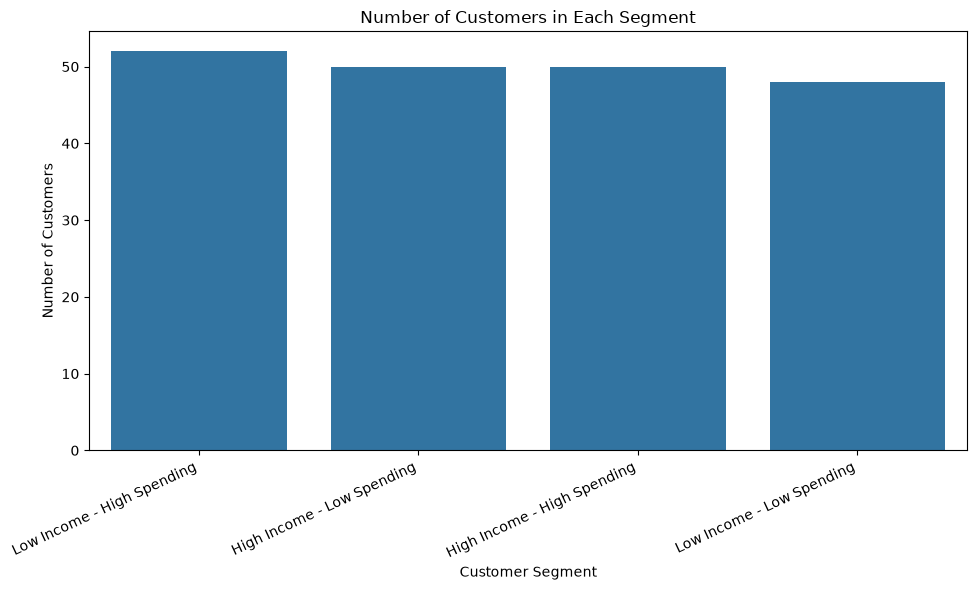

In [12]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="customer_segment",
    order=df["customer_segment"].value_counts().index
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [13]:
print("CUSTOMER SEGMENT BUSINESS RECOMMENDATIONS")
print("-" * 45)

for segment, row in segment_analysis.iterrows():
    print(f"\n{segment}")
    print(f"Customers: {int(row['customer_count'])}")

    if segment == "High Income - High Spending":
        print("Recommendation: Offer loyalty rewards and premium products.")
    elif segment == "High Income - Low Spending":
        print("Recommendation: Use personalized offers to encourage purchases.")
    elif segment == "Low Income - High Spending":
        print("Recommendation: Offer affordable bundles and targeted discounts.")
    else:
        print("Recommendation: Use budget-friendly promotions to improve engagement.")

CUSTOMER SEGMENT BUSINESS RECOMMENDATIONS
---------------------------------------------

High Income - High Spending
Customers: 50
Recommendation: Offer loyalty rewards and premium products.

High Income - Low Spending
Customers: 50
Recommendation: Use personalized offers to encourage purchases.

Low Income - High Spending
Customers: 52
Recommendation: Offer affordable bundles and targeted discounts.

Low Income - Low Spending
Customers: 48
Recommendation: Use budget-friendly promotions to improve engagement.


In [14]:
df.to_csv("customer_spending_segments.csv", index=False)
segment_analysis.to_csv("customer_segment_analysis.csv")

print("Files exported successfully!")

Files exported successfully!


In [15]:
print("FINAL PROJECT VALIDATION")
print("=" * 40)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Customer segments:", df["customer_segment"].nunique())

print("\nSegment distribution:")
display(df["customer_segment"].value_counts())

assert "customer_segment" in df.columns
assert df["customer_segment"].notna().all()

print("\nValidation completed successfully!")

FINAL PROJECT VALIDATION
Dataset shape: (200, 6)
Missing values: 0
Duplicate rows: 0
Customer segments: 4

Segment distribution:


customer_segment
Low Income - High Spending     52
High Income - Low Spending     50
High Income - High Spending    50
Low Income - Low Spending      48
Name: count, dtype: int64


Validation completed successfully!


# Day 33 – AI-Based Customer Spending Prediction

## Project Progress: Customer Segmentation and Business Insights

### Objective
Analyze customer income and spending behavior to identify customer groups and generate useful business recommendations.

### Work Completed
- Loaded and inspected the customer dataset.
- Cleaned and standardized column names.
- Segmented customers using median annual income and spending score.
- Visualized customer distribution using scatter plots and count plots.
- Analyzed customer counts and average spending behavior by segment.
- Generated business recommendations for each customer segment.
- Exported customer segmentation and analysis results to CSV files.
- Validated the segmentation results.

### Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.

### Outcome
The notebook identifies four customer segments based on income and spending behavior. The resulting analysis can support targeted marketing, customer engagement, and promotional planning.

### Next Step
Develop and evaluate a machine learning model to predict customer spending categories.